# My Content — comparer deux approches de recommandation

**Besoin métier :** proposer cinq articles pertinents, intégrer de nouveaux utilisateurs et pouvoir personnaliser les suggestions d'articles sans clic lorsqu'un embedding est disponible.

Deux modèles distincts sont entraînés et comparés : **filtrage collaboratif article–article** et **filtrage basé sur le contenu**. La popularité constitue un repère commun et un repli explicite. Aucun mélange des scores des deux modèles n'est effectué.

Le notebook présente la préparation, les algorithmes, la comparaison chronologique, les exemples concrets, la décision métier et l'export destiné à l'interface et à Azure Functions.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "data" / "brut").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import load_data, time_periods, prepare_catalog
from src.train import fit_models
from src.evaluate import evaluation_events, evaluate, choose_method
from src.experiment import comparative_examples, save_results
from src.recommender import Recommender

MAX_CASES = 2000
DIMENSIONS = 64
SAMPLE = False
OUTPUT = ROOT / "models"

## 1. Données et qualité

Les fichiers Globo.com fournissent des interactions implicites, des métadonnées et des embeddings de 250 dimensions. Un clic indique un intérêt possible ; une absence de clic n'est pas un rejet. Les titres et textes ne sont pas disponibles.

Les doublons exacts et lignes incomplètes sont retirés. Une règle de session de 24 heures retire les clics antérieurs au début de session ou très tardifs ; elle évite que quelques sessions décalées déplacent artificiellement la période d'évaluation. Le nombre de lignes retirées est affiché. Cette règle est une hypothèse de préparation.

Les données originales sont conservées dans `data/brut/`.

Les consultations antérieures à la publication indiquée dans les métadonnées sont également exclues. Cette règle est commune aux deux modèles et évite un historique incohérent avec le catalogue disponible.

In [2]:
clicks, metadata, embeddings, quality = load_data(ROOT / "data/brut", sample=SAMPLE)
display(pd.Series(quality, name="Contrôles de préparation"))
display(pd.Series({
    "utilisateurs": clicks.user_id.nunique(),
    "articles consultés": clicks.click_article_id.nunique(),
    "articles avec embedding": len(metadata),
    "dimension d'origine": embeddings.shape[1],
    "première consultation": pd.to_datetime(clicks.click_timestamp.min(), unit="ms", utc=True),
    "dernière consultation": pd.to_datetime(clicks.click_timestamp.max(), unit="ms", utc=True),
    "dernière création": pd.to_datetime(metadata.created_at_ts.max(), unit="ms", utc=True),
}))
display(clicks.head(), metadata.head())

raw_clicks             2988181
files                      385
missing_rows                 0
outside_24h_session       7331
duplicates                   0
before_publication        3289
retained_clicks        2977561
Name: Contrôles de préparation, dtype: int64

utilisateurs                                         322758
articles consultés                                    45551
articles avec embedding                              364047
dimension d'origine                                     250
première consultation      2017-10-01 03:00:00.026000+00:00
dernière consultation      2017-10-18 02:35:43.980000+00:00
dernière création                 2018-03-13 12:12:30+00:00
dtype: object

,user_id,click_article_id,click_timestamp
0,0,157541,1506826828020
1,0,68866,1506826858020
2,0,96755,1507340033155
3,0,313996,1507340063155
4,0,160158,1507388090915


,article_id,category_id,created_at_ts,publisher_id,words_count
0,0,0,1513144419000,0,168
1,1,1,1405341936000,0,189
2,2,1,1408667706000,0,250
3,3,1,1408468313000,0,230
4,4,1,1407071171000,0,162


## 2. Protocole commun

Les 48 dernières heures de consultations retenues forment le **test** ; les 48 précédentes la **validation**. Les modèles sont reconstruits toutes les six heures, exclusivement avec les clics antérieurs à chaque fenêtre. Les clics des fenêtres précédentes alimentent les suivantes, comme dans un service régulièrement actualisé.

Un cas est le premier clic inédit dans une fenêtre d'un utilisateur déjà connu avant celle-ci. Un échantillon déterministe de 2 000 cas par période utilise la graine 42. Un même utilisateur peut apparaître dans plusieurs fenêtres ; les résultats ne sont pas des observations indépendantes de personnes.

Les deux méthodes et le repère populaire utilisent les **mêmes cas, candidats, dates et exclusions**. Les candidats sont publiés avant la requête, pendant les sept derniers jours. Si moins de cinq existent, la recherche s'étend à trente jours puis aux articles plus anciens. Les articles déjà lus sont exclus. Les cibles absentes des candidats comptent comme des échecs.

La dernière création ou consultation est considérée comme aujourd'hui pour la démonstration. Cette simulation ne déplace pas les frontières historiques du test et ne crée pas de nouvelles consultations.

In [3]:
periods = time_periods(clicks)
display(pd.Series({name: pd.to_datetime(value, unit="ms", utc=True)
                   for name, value in periods.items()}, name="Périodes UTC"))

validation_start   2017-10-14 02:35:43.981000+00:00
test_start         2017-10-16 02:35:43.981000+00:00
end                2017-10-18 02:35:43.981000+00:00
Name: Périodes UTC, dtype: datetime64[ns, UTC]

## 3. Algorithmes

### Filtrage collaboratif : voisins d'articles par cosinus

Une matrice binaire **utilisateurs × articles** est construite avec les 20 dernières consultations de chaque utilisateur, sans répétition d'une même paire. Deux articles sont similaires lorsqu'ils sont consultés par les mêmes lecteurs.

$$s(i,j)=\frac{n(i,j)}{\sqrt{n(i)n(j)}}$$

On conserve les 50 meilleurs voisins de chaque article. Le score d'un candidat est la somme des similarités avec les dix dernières lectures de l'utilisateur, pondérées par $0{,}8^r$ selon leur rang de récence. Cette méthode utilise les comportements et ne consulte pas les embeddings.

**Avantage attendu :** découvertes fondées sur les intérêts collectifs, au-delà de la seule ressemblance des contenus. **Limites :** article sans interaction, matrice peu renseignée, influence des articles populaires. Ces effets seront mesurés.

### Filtrage basé sur le contenu : profil et cosinus

L'ACP réduit les embeddings à 64 dimensions. Elle est ajustée uniquement sur les articles consultés et publiés avant validation, puis reste fixe. Le profil utilisateur est la moyenne normalisée des dix derniers vecteurs lus, pondérée par $0{,}8^r$.

$$p_u=\operatorname{norm}\left(\sum_r0{,}8^r v_{i_r}\right),\qquad score(u,i)=p_u^Tv_i$$

Les scores ne contiennent ni popularité ni signal collaboratif. Les articles jamais consultés peuvent être classés si leur embedding existe.

**Avantage attendu :** démarrage avec peu de préférences et prise en compte d'articles sans clic. **Limites :** qualité des embeddings, répétition des thèmes, incapacité à personnaliser sans préférence.

### Repli commun

Sans historique ou si le collaboratif ne fournit pas cinq candidats positifs, les places restantes utilisent la popularité observée avant la coupure, puis la date de publication en cas d'égalité. Chaque suggestion indique si elle est personnalisée ou issue du repli.

Références : [Sarwar et al., 2001](https://files.grouplens.org/papers/www10_sarwar.pdf), [Pazzani et Billsus, 2007](https://doi.org/10.1007/978-3-540-72079-9_10), [cosinus](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html), [ACP](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

In [4]:
catalog, variance = prepare_catalog(
    metadata, embeddings, clicks, periods["validation_start"], dimensions=DIMENSIONS
)
print("Dimensions conservées :", catalog["vectors"].shape[1])
print("Variance expliquée :", f"{variance:.2%}")

Dimensions conservées : 64
Variance expliquée : 97.24%


## 4. Validation et décision métier

La décision est prise **avant de mesurer le test**. L'exigence du MVP est de pouvoir attribuer un score personnalisé à un article sans clic. On retient d'abord les approches qui démontrent cette capacité sur validation, puis celle ayant le meilleur Hit Rate@5 et, en cas d'égalité, le meilleur MRR@5.

Ce choix peut être différent du modèle maximisant la pertinence sur des articles connus. Le meilleur modèle pour cet autre objectif est également indiqué. La contrainte métier est déclarée avant les résultats.

In [5]:
validation_events, validation_count = evaluation_events(
    clicks, periods["validation_start"], periods["test_start"], MAX_CASES
)
validation, validation_details = evaluate(clicks, catalog, validation_events)
display(pd.DataFrame(validation["methods"]).T.drop(columns="target_groups"))
decision = choose_method(validation, require_new_articles=True)
display(pd.Series(decision, name="Décision figée avant le test"))

Fenêtre 2017-10-14 02:35:43.981000+00:00 : 120 cas


CF ajusté : 2,596,385 clics, 763,582 voisins, 1.2 s


Fenêtre 2017-10-14 08:35:43.981000+00:00 : 301 cas


CF ajusté : 2,607,469 clics, 765,910 voisins, 1.2 s


Fenêtre 2017-10-14 14:35:43.981000+00:00 : 329 cas


CF ajusté : 2,635,941 clics, 775,421 voisins, 1.3 s


... (8 outputs left out)

Fenêtre 2017-10-15 20:35:43.981000+00:00 : 469 cas


CF ajusté : 2,740,309 clics, 820,761 voisins, 1.3 s


,cases,hits,hit_rate_at_5,mrr_at_5,ndcg_at_5,catalog_coverage_at_5,fallback_share,distinct_categories,category_concentration,dominant_history_share,intra_list_similarity,new_article_share,personalized_new_article_share,mean_readers,mean_age_hours,median_latency_ms
collaborative,2000,42,0.021,0.01175,0.014033,0.214105,0.0078,4.199,0.3453,0.1113,0.111753,0.0,0.0,8754.8127,78.398217,1.8363
content,2000,30,0.015,0.0071,0.00903,0.416825,0.0,2.2075,0.7256,0.3839,0.662819,0.0431,0.0431,584.9419,82.470475,2.19685
popular,2000,21,0.0105,0.002583,0.004472,0.003637,1.0,3.7475,0.4148,0.0423,0.1041,0.0,0.0,20708.7187,105.893713,2.41085


selected_method                                                                content
best_validation_accuracy                                                 collaborative
require_personalized_new_articles                                                 True
eligible_methods                                                             [content]
selection_data                                                         validation_only
reason                               Personnaliser des articles sans clic est une e...
Name: Décision figée avant le test, dtype: object

## 5. Test final

- **Hit Rate@5** : le prochain article cliqué est-il présent parmi les cinq suggestions ?
- **MRR@5 et NDCG@5** : à quel rang est-il placé ?
- **Couverture** : part de l'union des candidats effectivement recommandée.
- **Diversité** : nombre de catégories, concentration dans une catégorie et similarité moyenne entre suggestions.
- **Nouveaux articles** : part sans lecteur dans l'entraînement, dont part réellement personnalisée.
- **Repli** : proportion des cinq places remplies par popularité ou fraîcheur.
- **Popularité et âge moyens** : biais possibles vers les contenus dominants ou anciens.

Les scores sont aussi séparés selon que la cible a déjà été consultée ou non dans l'entraînement. La similarité et la concentration décrivent les suggestions ; elles ne démontrent pas un effet causal de bulle ni la satisfaction.

Fenêtre 2017-10-16 02:35:43.981000+00:00 : 114 cas


CF ajusté : 2,783,145 clics, 831,845 voisins, 1.3 s


Fenêtre 2017-10-16 08:35:43.981000+00:00 : 695 cas


CF ajusté : 2,792,839 clics, 833,731 voisins, 1.3 s


Fenêtre 2017-10-16 14:35:43.981000+00:00 : 716 cas


CF ajusté : 2,861,575 clics, 855,158 voisins, 1.3 s


... (7 outputs left out)

CF ajusté : 2,977,424 clics, 896,542 voisins, 1.4 s


,cases,hits,hit_rate_at_5,mrr_at_5,ndcg_at_5,catalog_coverage_at_5,fallback_share,distinct_categories,category_concentration,dominant_history_share,intra_list_similarity,new_article_share,personalized_new_article_share,mean_readers,mean_age_hours,median_latency_ms
collaborative,2000,40,0.02,0.010633,0.012954,0.176652,0.0086,4.201,0.3453,0.1084,0.112883,0.0,0.0,9059.6943,95.858684,1.81495
content,2000,25,0.0125,0.00625,0.007775,0.351764,0.0,2.221,0.7187,0.3675,0.665927,0.051,0.051,575.7658,85.962126,2.1458
popular,2000,32,0.016,0.004008,0.006883,0.00308,1.0,4.269,0.3314,0.0392,0.03928,0.0,0.0,20142.3596,124.166187,2.3761


,new_article,known_article
collaborative,"{'cases': 402, 'hit_rate_at_5': 0.0}","{'cases': 1598, 'hit_rate_at_5': 0.02503128911..."
content,"{'cases': 402, 'hit_rate_at_5': 0.014925373134...","{'cases': 1598, 'hit_rate_at_5': 0.01188986232..."
popular,"{'cases': 402, 'hit_rate_at_5': 0.0}","{'cases': 1598, 'hit_rate_at_5': 0.02002503128..."


Cas : 2000 — utilisateurs : 1988
Part de cibles disponibles : 98.45%


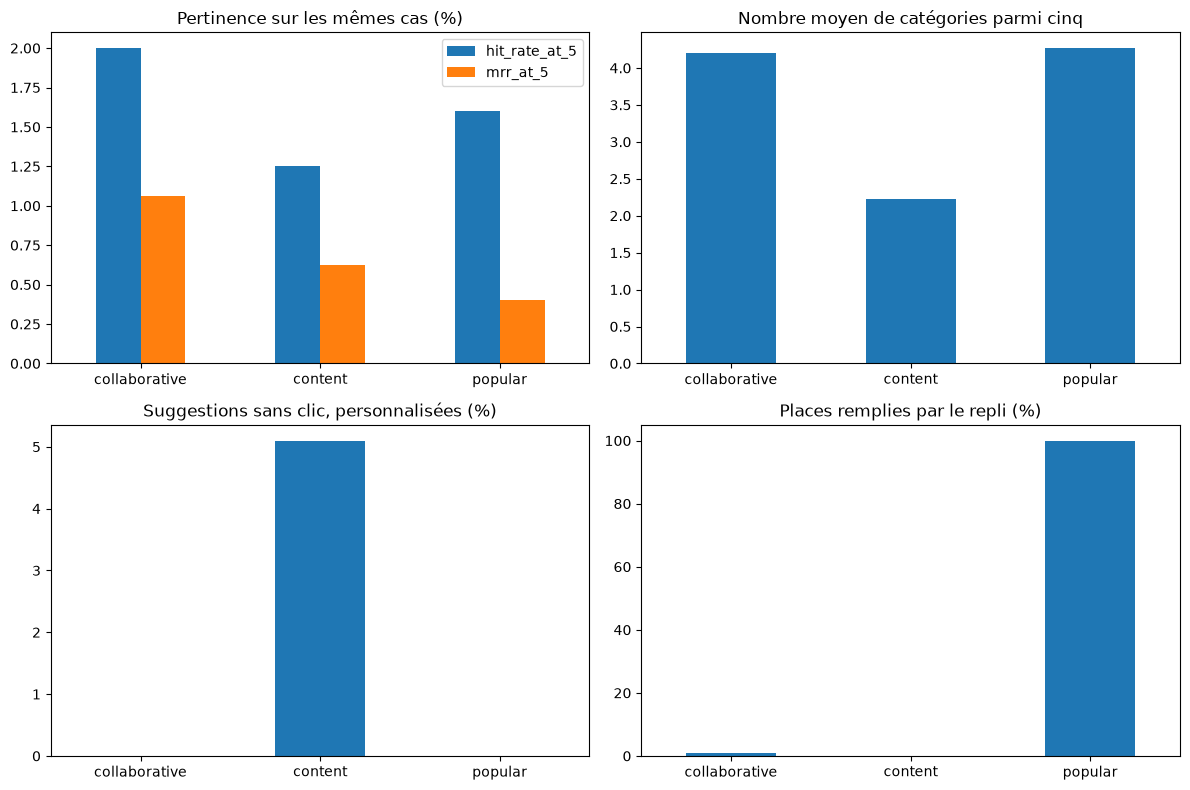

**collaborative** : 40 cibles sur 2000, Hit Rate@5 **2.00%**, MRR@5 **0.0106**.

**content** : 25 cibles sur 2000, Hit Rate@5 **1.25%**, MRR@5 **0.0063**.

In [6]:
test_events, test_count = evaluation_events(
    clicks, periods["test_start"], periods["end"], MAX_CASES
)
test, test_details = evaluate(clicks, catalog, test_events)
results = pd.DataFrame(test["methods"]).T
display(results.drop(columns="target_groups"))
display(pd.DataFrame({
    method: values["target_groups"]
    for method, values in test["methods"].items()
}).T)
print("Cas :", test["cases"], "— utilisateurs :", test["unique_users"])
print("Part de cibles disponibles :", f"{test['candidate_recall']:.2%}")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
(results[["hit_rate_at_5", "mrr_at_5"]].astype(float) * 100).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set_title("Pertinence sur les mêmes cas (%)")
results["distinct_categories"].astype(float).plot.bar(ax=axes[0, 1], rot=0)
axes[0, 1].set_title("Nombre moyen de catégories parmi cinq")
(results["personalized_new_article_share"].astype(float) * 100).plot.bar(ax=axes[1, 0], rot=0)
axes[1, 0].set_title("Suggestions sans clic, personnalisées (%)")
(results["fallback_share"].astype(float) * 100).plot.bar(ax=axes[1, 1], rot=0)
axes[1, 1].set_title("Places remplies par le repli (%)")
plt.tight_layout()
plt.show()

for method in ("collaborative", "content"):
    value = test["methods"][method]
    display(Markdown(
        f"**{method}** : {value['hits']} cibles sur {value['cases']}, "
        f"Hit Rate@5 **{value['hit_rate_at_5']:.2%}**, MRR@5 **{value['mrr_at_5']:.4f}**."
    ))

## 6. Modèles finaux et situations concrètes

Les deux approches sont réajustées sur tous les clics retenus. Le catalogue complet et les paramètres d'ACP sont conservés.

Deux exemples sont extraits de la **validation**, pour ne pas sélectionner une anecdote sur le test :
1. une différence de concentration des catégories entre suggestions ;
2. un véritable article sans consultation avant la coupure, proposé par le contenu.

L'exemple de concentration est choisi pour illustrer un contraste ; sa conclusion n'est pas généralisée. Les moyennes globales permettent de vérifier si ce contraste est représentatif. Un troisième scénario montre le nouvel utilisateur sans historique puis avec une préférence déclarée.

In [7]:
production_model = fit_models(clicks, catalog)
production_model.selected_method = decision["selected_method"]
scenarios = comparative_examples(production_model, clicks, validation_details)
display(pd.Series(scenarios["current_catalog"], name="Catalogue à la date simulée"))
display(pd.Series(scenarios["concentration"], name="Exemple : concentration"))
display(pd.Series(scenarios["new_article"], name="Exemple : article sans clic"))
display(pd.DataFrame({
    method: {"sans_historique": result["article_ids"],
             "avec_preference": scenarios["new_user"]["with_first_preference"][method]["article_ids"]}
    for method, result in scenarios["new_user"]["without_history"].items()
}).T)

CF ajusté : 2,977,561 clics, 897,403 voisins, 1.4 s


reference_time              1520943150000
cutoff                      1508294143981
candidate_articles                  13752
articles_without_readers            13752
example_known_user                 322896
Name: Catalogue à la date simulée, dtype: int64

title                             Concentration des recommandations : un risque ...
user_id                                                                        1956
snapshot_time                                                         1507948543981
history                           [283764, 284793, 236566, 107272, 111321, 31392...
content_articles                           [283116, 283458, 283192, 284066, 286007]
collaborative_articles                       [271262, 58580, 225010, 96210, 284583]
content_categories                                        [412, 412, 412, 412, 412]
collaborative_categories                                  [399, 118, 354, 209, 412]
content_concentration                                                           1.0
collaborative_concentration                                                     0.2
content_intra_similarity                                                   0.596385
collaborative_intra_similarity                                             0

title                        Article sans consultation dans l'apprentissage
user_id                                                               99736
article_id                                                           202652
training_clicks                                                           0
snapshot_time                                                 1507970143981
history                   [61395, 285533, 149706, 208150, 202670, 202635...
content_articles                   [202637, 203199, 202388, 202652, 203264]
collaborative_articles             [208562, 348112, 202388, 202476, 202637]
content_rank                                                              4
is_actual_next_click                                                   True
interpretation            Le contenu peut classer cet article grâce à so...
Name: Exemple : article sans clic, dtype: object

,sans_historique,avec_preference
collaborative,"[39891, 263284, 347438, 70039, 342184]","[39891, 263284, 347438, 70039, 342184]"
content,"[39891, 263284, 347438, 70039, 342184]","[22992, 22529, 22239, 22956, 22450]"


## 7. Export et vérification

L'artefact NPZ contient les deux modèles, les profils, les articles lus, le catalogue et l'ACP. La méthode choisie est enregistrée. Les poids restent en float32 et le rechargement doit conserver les classements.

L'interface charge ce fichier en local. À terme, une Azure Function chargera la même version depuis Blob Storage privé et utilisera la même classe NumPy pour renvoyer cinq articles. Aucun réentraînement n'a lieu au clic sur le bouton de recommandation.

In [8]:
metrics = save_results(
    OUTPUT, production_model, quality, periods, variance, validation, test, decision,
    validation_count, test_count, validation_details + test_details, scenarios, SAMPLE
)
loaded = Recommender.load(OUTPUT / "recommender.npz")
for user_id in loaded.data["user_ids"][-3:]:
    for method in ("collaborative", "content"):
        result = loaded.recommend(int(user_id), method)
        assert len(set(result["article_ids"])) == 5
        assert set(result["article_ids"]).isdisjoint(loaded.history(int(user_id)))
        assert result == production_model.recommend(int(user_id), method)
print("Méthode retenue :", loaded.selected_method)
print("Référence considérée comme aujourd'hui :", pd.to_datetime(loaded.reference_time, unit="ms", utc=True))
print("Taille de l'artefact :", round(metrics["artifact_bytes"] / 1024**2, 1), "Mio")
print("Classements conservés après rechargement.")

Méthode retenue : content
Référence considérée comme aujourd'hui : 2018-03-13 12:12:30+00:00
Taille de l'artefact : 166.4 Mio
Classements conservés après rechargement.


## 8. Nouveaux utilisateurs, nouveaux articles et limites

| Situation | Collaboratif | Contenu |
|---|---|---|
| Utilisateur sans préférence | Repli commun, aucune personnalisation | Même repli, aucune personnalisation |
| Première préférence sur un article connu | Utilise ses voisins comportementaux | Crée immédiatement un profil |
| Première préférence sur un article sans clic | Voisins absents ; repli | Exploite son embedding |
| Nouvel article avec embedding | Pas de score collaboratif avant interactions et mise à jour | Peut être personnalisé dès son ajout au catalogue |
| Exploration | Relations entre intérêts collectifs | Risque de répétition des contenus proches |
| Données nécessaires | Interactions utilisateurs–articles | Embeddings et préférences utilisateur |

La date globale du catalogue peut être postérieure de plusieurs mois aux consultations. Les candidats récents de la démonstration peuvent donc ne posséder aucun clic ; le CF utilise alors le repli. Les métriques mesurées en octobre ne représentent pas une évaluation en mars sans nouveaux clics.

La préparation d'un article inédit demande un embedding compatible. Le jeu ne contient ni le texte historique ni l'encodeur d'origine : on ne peut pas prétendre encoder directement un nouveau texte avec les seuls fichiers fournis.

Pour suivre un véritable effet de bulle, il faudrait enregistrer des impressions et des lectures sur plusieurs périodes et comparer leur évolution. [Nguyen et al., 2014](https://doi.org/10.1145/2566486.2568012) étudient ce sujet. Ici, on se limite à des indicateurs de concentration et à des exemples reproductibles.

Le fichier `docs/bareme.md` relie les critères aux preuves et indique les tâches encore à réaliser : déploiement Azure réel et partage GitHub de la version finale.